## Import the neccessary libraries

In [211]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import re
from sklearn.preprocessing import OrdinalEncoder
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from category_encoders.target_encoder import TargetEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV


In [212]:
df = pd.read_csv(r"C:\Users\name\Desktop\BIG FOLDER\PROJECTS\My_Projects\ghana_house_rent_project\data\processed_house_rentals.csv")
df.head()

,price,category,bedrooms,bathrooms,floor_area,condition,amenities,region,locality,is_furnished
0,9196,Flats,2,2,145,Used,"['24-hour Electricity', 'Air Conditioning', 'B...",Greater Accra,East Legon,Semi-Furnished
1,7500,Flats,2,2,100,Used,"['24-hour Electricity', 'Air Conditioning', 'A...",Greater Accra,Dzorwulu,Unfurnished
2,11200,Detached,4,5,100,New,"['Tiled Floor', 'Chandelier', 'Dining Area', '...",Greater Accra,Ashaley Botwe,Semi-Furnished
3,2500,Detached,3,3,17,Used,"['Pop Ceiling', 'Pre-Paid Meter', '24-hour Ele...",Greater Accra,Teshie,Semi-Furnished
4,9146,Detached,3,3,160,Used,"['Pre-Paid Meter', 'Dining Area', 'Chandelier'...",Greater Accra,Spintex,Semi-Furnished


## Build a pipeline

### Multi-hot encoder

In [213]:
def clean_amenities(amenity_str):
    amenities = amenity_str.split(',')
    cleaned = []
    for a in amenities:
        a = a.strip()
        a = re.sub(r"[\[\]']", "", a)  # remove [, ], '
        a = a.title()                  # standardize casing
        cleaned.append(a)
    return cleaned


In [214]:
df['amenities'] = df['amenities'].apply(clean_amenities)


In [215]:
from itertools import chain

unique_amenities = set(chain.from_iterable(df['amenities']))
sorted(list(unique_amenities))[:20]


['24-Hour Electricity',
 'Air Conditioning',
 'Apartment',
 'Balcony',
 'Chandelier',
 'Dining Area',
 'Dishwasher',
 'Hot Water',
 'Kitchen Cabinets',
 'Kitchen Shelf',
 'Microwave',
 'Pop Ceiling',
 'Pre-Paid Meter',
 'Refrigerator',
 'Tiled Floor',
 'Tv',
 'Wardrobe',
 'Wi-Fi']

In [216]:
class MultiHotEncoder(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.mlb = MultiLabelBinarizer(sparse_output=False)

    def _rows(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.iloc[:, 0]              # the single amenities column
        elif isinstance(X, np.ndarray):
            X = X.ravel()
        return [list(x) if isinstance(x, (list, tuple, set)) else [x] for x in X]

    def fit(self, X, y=None):
        self.mlb.fit(self._rows(X))
        return self

    def transform(self, X):
        return self.mlb.transform(self._rows(X))

    def get_feature_names_out(self, input_features=None):
        return np.array(self.mlb.classes_)

### Split data


In [217]:
X = df.drop('price', axis=1)
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Define features

In [218]:
numeric_features = ['bedrooms','bathrooms','floor_area']
ordinal_features = ['condition','is_furnished']
multi_hot_features = ['amenities']
target_encoded_features = ['locality','region','category']

### Create transformers and preprocessor

In [219]:
numeric_transformer = StandardScaler()
ordinal_transformer = OrdinalEncoder()
multi_hot_transformer = MultiHotEncoder()
target_transformer = TargetEncoder()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('multihot', multi_hot_transformer, multi_hot_features),
        ('target', target_transformer, target_encoded_features)
    ]
)


### Linear Regression

In [220]:
linreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train and predict
linreg_pipeline.fit(X_train, y_train)
y_pred = linreg_pipeline.predict(X_test)

# Metrics
print("Linear Regression Results")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))


Linear Regression Results
RMSE: 3101.4797856106743
MAE: 2166.662241829894
R²: 0.6324305584599894


The average prediction for this model is off by ₵2,166.66p and approximately 63% of the variation in rent prices is explained the input variables. This indicates that the model is quite performing.

### Lasso Regression

In [221]:
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=0.1, random_state=42))
])

# Train and predict
lasso_pipeline.fit(X_train, y_train)
y_pred = lasso_pipeline.predict(X_test)

# Metrics
print("Lasso Regression Results")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))


Lasso Regression Results
RMSE: 3101.4492664949435
MAE: 2166.594482352103
R²: 0.632437792322473


### Ridge Regression

In [222]:
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])

# Train and predict
ridge_pipeline.fit(X_train, y_train)
y_pred = ridge_pipeline.predict(X_test)

# Metrics
print("Ridge Regression Results")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))


Ridge Regression Results
RMSE: 3101.4798007324875
MAE: 2166.6475441375487
R²: 0.6324305548756897


### Elastic Net Regression

In [223]:
elastic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42))
])

# Train and predict
elastic_pipeline.fit(X_train, y_train)
y_pred = elastic_pipeline.predict(X_test)

# Metrics
print("Elastic Net Regression Results")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))


Elastic Net Regression Results
RMSE: 3112.1526190493278
MAE: 2166.7259807116934
R²: 0.6298964407882162


## Hyperparameter Tuning for Ridge, Lasso, ElasticNet

### A helper function for tuning

In [224]:
def tune_model(model_name, model, param_grid, X_train, y_train, preprocessor):
    """
    Hyperparameter tuning for a regression model.
    
    Args:
        model_name: str, name of the model
        model: sklearn regressor instance
        param_grid: dict, hyperparameters to tune
        X_train, y_train: training data
        preprocessor: ColumnTransformer for preprocessing
    
    Returns:
        best_pipeline: pipeline with best hyperparameters
        best_params: best parameters found
    """
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring='neg_mean_squared_error',
        cv=5,  # 5-fold cross-validation
        n_jobs=-1
    )
    
    grid_search.fit(X_train, y_train)
    
    print(f"Best parameters for {model_name}: {grid_search.best_params_}")
    print(f"Best CV RMSE: {np.sqrt(-grid_search.best_score_):.2f}\n")
    
    return grid_search.best_estimator_


### Define the hyperparameter grids

In [225]:
# Ridge hyperparameters
ridge_param_grid = {
    'regressor__alpha': [0.01, 0.1, 1.0, 10, 50, 100]
}

# Lasso hyperparameters
lasso_param_grid = {
    'regressor__alpha': [0.001, 0.01, 0.1, 1.0, 10]
}

# ElasticNet hyperparameters
elastic_param_grid = {
    'regressor__alpha': [0.001, 0.01, 0.1, 1.0],
    'regressor__l1_ratio': [0.2, 0.5, 0.8]
}


### Run tuning for each model

In [226]:
# Ridge
best_ridge = tune_model('Ridge', Ridge(random_state=42), ridge_param_grid, X_train, y_train, preprocessor)

# Lasso
best_lasso = tune_model('Lasso', Lasso(random_state=42, max_iter=10000), lasso_param_grid, X_train, y_train, preprocessor)

# ElasticNet
best_elastic = tune_model('ElasticNet', ElasticNet(random_state=42, max_iter=10000), elastic_param_grid, X_train, y_train, preprocessor)


Best parameters for Ridge: {'regressor__alpha': 50}
Best CV RMSE: 3090.63

Best parameters for Lasso: {'regressor__alpha': 0.001}
Best CV RMSE: 3090.71

Best parameters for ElasticNet: {'regressor__alpha': 0.01, 'regressor__l1_ratio': 0.5}
Best CV RMSE: 3090.63



### Evaluate tuned models on test set

In [227]:
def evaluate_model(model_name, pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{model_name} Test Metrics:")
    print(f"RMSE: {rmse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}\n")

evaluate_model('Ridge', best_ridge, X_test, y_test)
evaluate_model('Lasso', best_lasso, X_test, y_test)
evaluate_model('ElasticNet', best_elastic, X_test, y_test)


Ridge Test Metrics:
RMSE: 3101.61, MAE: 2166.03, R²: 0.63

Lasso Test Metrics:
RMSE: 3101.48, MAE: 2166.66, R²: 0.63

ElasticNet Test Metrics:
RMSE: 3101.66, MAE: 2165.93, R²: 0.63



## Save the best model

In [228]:
best_model = best_lasso  
import joblib

# Save the entire pipeline (preprocessing + model)
joblib.dump(best_model, r"C:\Users\name\Desktop\BIG FOLDER\PROJECTS\My_Projects\ghana_house_rent_project\model\final_model.pkl")


['C:\\Users\\name\\Desktop\\BIG FOLDER\\PROJECTS\\My_Projects\\ghana_house_rent_project\\model\\final_model.pkl']

## Compare Predictions vs Actual

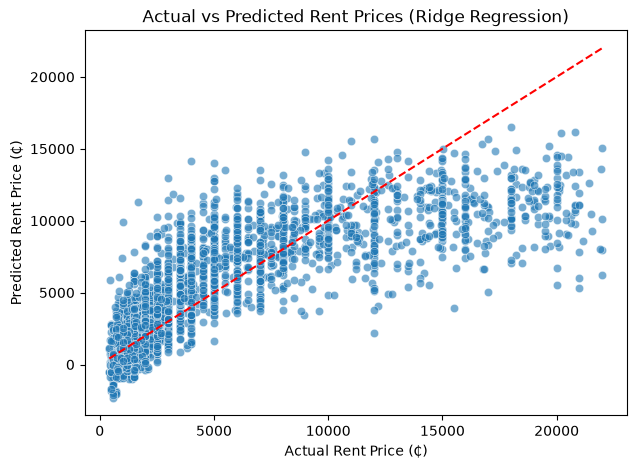

In [229]:
plt.figure(figsize=(7,5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.xlabel("Actual Rent Price (₵)")
plt.ylabel("Predicted Rent Price (₵)")
plt.title("Actual vs Predicted Rent Prices (Ridge Regression)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.show()

## Residual Analysis

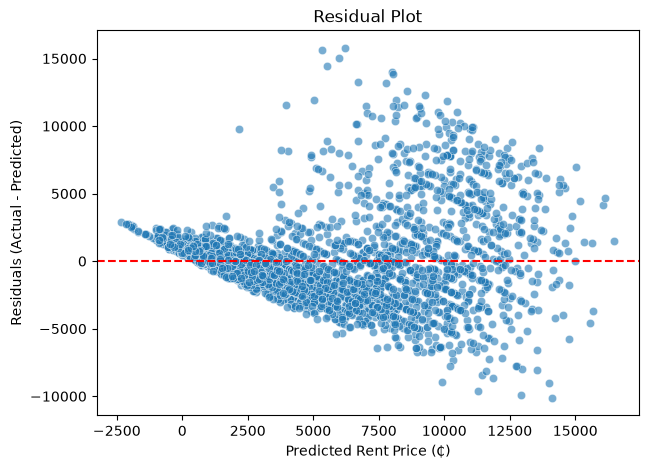

In [230]:
residuals = y_test - y_pred

plt.figure(figsize=(7,5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Rent Price (₵)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

The residual plot follows a pattern which suggests that the model overpredict or underpredict in some price range.

## Residual Distribution

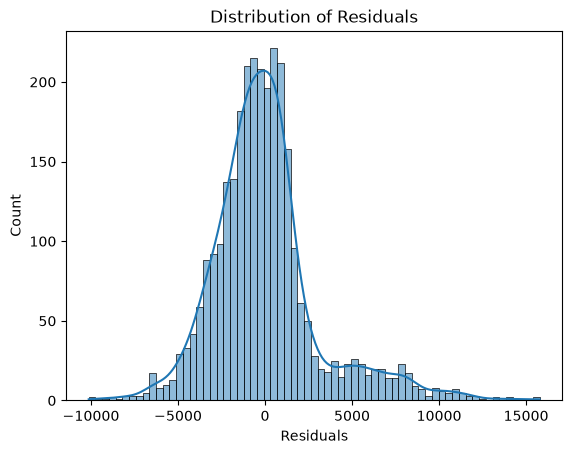

In [231]:
sns.histplot(residuals, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.show()


The residuals approximately follow a bell-shaped distribution, suggesting a reasonable model fit. However, the distribution displays positive skewness and heavy tails, particularly on the right side, implying that the model tends to underestimate prices for higher-valued properties. The presence of outliers indicates that extreme observations are not well captured by the model, which may be due to unobserved factors or nonlinear relationships.

## Feature Importance

In [232]:
# Get feature names after preprocessing
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

# Get coefficients from the final estimator
coefs = best_model.named_steps['regressor'].coef_.ravel()   # use .coef_ for regression too

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefs,
    'abs_coefficient': np.abs(coefs)
})

In [233]:
def group_features(feature_name):
    # Combine all amenities
    if feature_name.startswith('multihot__'):
        return 'amenities'
    
    # Combine parking space (binary)
    if feature_name.startswith('binary__parking_space'):
        return 'parking_space'
    
    # Otherwise, keep feature as-is (strip transformer prefix)
    return feature_name.split('__', 1)[-1]


feature_importance['group'] = feature_importance['feature'].apply(group_features)

group_importance = (
    feature_importance
    .groupby('group')['abs_coefficient']
    .sum()
    .sort_values(ascending=False)
)

group_importance


group
amenities       9157.441810
bedrooms         844.366110
bathrooms        714.578584
is_furnished     642.895843
floor_area       122.566104
condition         94.024728
locality           0.553324
category           0.335119
region             0.209485
Name: abs_coefficient, dtype: float64

The feature importance results indicate that housing prices are primarily driven by property-level characteristics rather than locational factors. Amenities emerge as the most influential predictor, highlighting the strong preference for comfort and convenience among buyers or renters. Structural features such as bedrooms, bathrooms, and furnishing status contribute moderately, while floor area and condition have relatively limited influence. In contrast, locality, category, and region exhibit negligible importance, suggesting that spatial variations in price are largely captured through amenities and housing features rather than geographic classification.

In [234]:
from sklearn.model_selection import cross_val_score

X = df.drop(columns='price')
y = df['price']

cv_scores = cross_val_score(
    best_lasso,        # your FULL pipeline
    X,
    y,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

rmse_scores = -cv_scores

print("Fold RMSE:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())
print("Std RMSE:", rmse_scores.std())


Fold RMSE: [2990.66326686 3152.0902343  3111.14303359 3087.13694575 3084.78171683]
Mean RMSE: 3085.1630394637273
Std RMSE: 53.081933346710905


In [235]:
from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    best_lasso,
    X,
    y,
    cv=5,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'mae': 'neg_mean_absolute_error',
        'r2': 'r2'
    }
)

print("RMSE:", -cv_results['test_rmse'].mean())
print("MAE :", -cv_results['test_mae'].mean())
print("R²  :",  cv_results['test_r2'].mean())


RMSE: 3085.1630394637273
MAE : 2154.649640852572
R²  : 0.6246610710865909


Using 5-fold cross-validation, the model explains approximately 62% of the variability in rental prices. On average, predicted rents differ from actual rents by about ₵2,155, with larger errors occasionally reaching around ₵3,085. This indicates a reasonably strong and reliable model for rent estimation, though some prediction uncertainty remains.